# Spatial stability analysis: growth rates and dominant spatial modes

This notebook analyzes the results of the linear spatial stability calculations performed by `spatial_stability.py`. It loads the eigenvalues obtained from the characteristic equation for different external input strengths and spatial wavenumbers, and identifies the dominant spatial mode at each input strength.

For each combination of external input and wavevector, the code selects the accepted eigenvalue with the largest real part. It then determines the maximum growth rate across the sampled wavevectors, together with the corresponding wavenumber magnitude and oscillation frequency.

The analysis produces plots of:

- The real part of the dominant eigenvalue as a function of external input, for different spatial wavenumbers.
- The wavenumber associated with the largest growth rate.
- The corresponding spatial wavelength, calculated as \(\lambda_{\mathrm{wave}} = 2\pi/|\mathbf{k}|\).
- The oscillation frequency of the dominant mode.

An optional power-law fit characterizes the dependence of the dominant wavenumber on external input.

Positive growth rates indicate linear instability, whereas negative growth rates indicate linearly stable modes. The maximally growing mode is identified regardless of whether its growth rate is positive or negative.

## Input data and configuration

The notebook reads MATLAB-compatible `.mat` files generated by the spatial stability calculations. Each file contains the results for one sampled wavevector, including the external input grid and candidate eigenvalues.

Before running the notebook, set `G` and `DATA_DIR` in the configuration cell to match the generated results. The filenames are constructed automatically from these parameters.

The analysis requires Python with NumPy, SciPy, and Matplotlib.

## Analysis and outputs

The dominant wavenumber is calculated directly from the accepted eigenvalues on the sampled spatial grid. Interpolation and smoothing are used only for visualization and do not affect the identification of the dominant mode.

Missing eigenvalues are represented as `NaN`. The wavelength is also set to `NaN` when the dominant wavenumber is zero.

The notebook displays the resulting figures and saves the derived quantities in MATLAB (`.mat`) and NumPy (`.npz`) formats for subsequent analysis.

The growth-rate figure is additionally exported in SVG format.
 

In [1]:
from pathlib import Path
import warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat, savemat
from scipy.interpolate import PchipInterpolator, Akima1DInterpolator, CubicSpline
from scipy.signal import savgol_filter
from scipy.optimize import minimize

G = 3.3
DATA_DIR = Path("results_paper4b_g3.3") #results from 201 simulations (more points for figure 4b)
OUTPUT_DIR = DATA_DIR / "plots"

 
INPUT_SCALE = 1.0  # Corrected sweep: saved input is already nu_ext/nt_alpha.
X_LABEL = r"$\nu_{\rm ext}/\nu_{\theta}$"

# Fallback ONLY for old files lacking k/list_k metadata.
 
MAX_LOG_OBJECTIVE = np.log(1e-4 + 1e-7)  # Same filter as pasted MATLAB; column 3 is log(|det|+1e-7).
# To require |det| <= 1e-4 instead, use np.log(1e-4 + 1e-7).

INTERPOLATION = "makima"  # "makima", "pchip", "spline", or "linear"
SMOOTH_DISPLAY = True
SMOOTH_WINDOW = 101
PT_MORE = 1000
OMIT_LAST_K_CURVES = 3  # Original first plot uses 1:N-3; all k enter peak search.
X_LIMITS = None
REFERENCE_X = []  # Optional vertical lines, in displayed x units.
FIT_X_RANGE = None  # e.g. (lower, upper); defaults to all positive-k points.
FIT_ONLY_UNSTABLE = False
plt.rcParams.update({"font.size": 16})

def result_path(index):
    stem =  f"Stability_26g{G:.2f}"
    return DATA_DIR / f"{stem}_fwd_{index}_extra2.mat"

print("Results folder:", DATA_DIR.resolve())


Results folder: /Users/ludovica/Documents/Documents_MAC/Duke/Brian_simulations/Paper_figures_simulations/GitHub_clean/theory/Fig4/results_paper4b_g3.3


In [2]:
first_path = result_path(1)
if not first_path.is_file():
    raise FileNotFoundError(f"{first_path}: set DATA_DIR to the folder containing the results.")

first = loadmat(first_path)
list_k = np.asarray(first["list_k"], dtype=float).ravel()
N = len(list_k)
Iext_list = np.asarray(first["list_varying_param"], float).ravel()
if Iext_list.size == 0 or not np.all(np.isfinite(Iext_list)):
    raise ValueError("Input grid is empty or contains nonfinite values.")
if np.any(np.diff(Iext_list) <= 0):
    raise ValueError("Expected a strictly increasing input grid.")
M = len(Iext_list)
peakReLambda = np.full((N, M), np.nan)
peakOmega = np.full((N, M), np.nan)   # omega associated with peak Re(lambda)
real_k = np.full(N, np.nan)

# Require the whole spatial grid: partial files can give misleading maxima over k.
missing = [str(result_path(i)) for i in range(1, N+1) if not result_path(i).is_file()]
if missing:
    raise FileNotFoundError(f"Missing {len(missing)} k files; first is {missing[0]}. "
                            "Wait for the sweep to finish, or check the filename/grid settings.")

for row in range(N):
    path = result_path(row+1)
    data = first if row == 0 else loadmat(path)
    inputs = np.asarray(data["list_varying_param"], float).ravel()
    if inputs.shape != Iext_list.shape or not np.allclose(inputs, Iext_list, rtol=1e-12, atol=1e-14):
        raise ValueError(f"Input grid differs in {path.name}")
    if "g" in data and not np.isclose(float(data["g"].item()), G):
        raise ValueError(f"g differs from G in {path.name}")
    if "list_k" in data and not np.array_equal(np.asarray(data["list_k"]).ravel(), list_k):
        raise ValueError(f"k grid differs in {path.name}")
    if "kx" in data and "ky" in data:
        real_k[row] = np.hypot(float(data["kx"].item()), float(data["ky"].item()))
    else:
        real_k[row] = np.sqrt(2) * list_k[row]
    roots_by_input = data["local_minima_all"].ravel(order="F")
    if len(roots_by_input) != M:
        raise ValueError(f"Cell array length differs in {path.name}")
    for j, roots in enumerate(roots_by_input):
        roots = np.asarray(roots, float)
        if not roots.size:
            continue
        if roots.ndim != 2 or roots.shape[1] != 3:
            raise ValueError(f"Expected three root columns in {path.name}, input {j}")
        valid = np.isfinite(roots).all(axis=1) & (roots[:, 2] <= MAX_LOG_OBJECTIVE)
        if valid.any():
            valid_roots = roots[valid]
        
            # Among the accepted eigenvalues for this (k, nu_ext),
            # select the one with the largest Re(lambda)
            i_peak = np.argmax(valid_roots[:, 0])
        
            peakReLambda[row, j] = valid_roots[i_peak, 0]
            peakOmega[row, j] = valid_roots[i_peak, 1]   # already in Hz

x_points = INPUT_SCALE * Iext_list
finite = np.isfinite(peakReLambda)
has_roots = finite.any(axis=0)
safe = np.where(finite, peakReLambda, -np.inf)
idx_max = safe.argmax(axis=0)
k_max_list = np.full(M, np.nan)
max_growth = np.full(M, np.nan)
k_max_list[has_roots] = real_k[idx_max[has_roots]]
max_growth[has_roots] = safe[idx_max[has_roots], np.flatnonzero(has_roots)]

omega_at_kmax = np.full(M, np.nan)

cols = np.flatnonzero(has_roots)
omega_at_kmax[has_roots] = peakOmega[idx_max[has_roots], cols]


k_points = k_max_list.copy()
if not has_roots.any():
    raise ValueError("No roots pass the filter.")
incomplete = np.sum(~finite.all(axis=0))
if incomplete:
    warnings.warn(f"{incomplete} inputs lack accepted roots at one or more k values; "
                  "their maxima are only over available roots.")
edge = has_roots & (idx_max == np.argmax(real_k))
if edge.any():
    warnings.warn(f"{edge.sum()} maxima lie at the largest sampled k; "
                  "the spatial search range may need extending.")
print(f"Loaded {N} k values and {M} input values.")


Loaded 201 k values and 100 input values.


/var/folders/8x/vglf00114n368pzflpydh3600000gn/T/ipykernel_50437/2080344102.py:79: UserWarning: 10 inputs lack accepted roots at one or more k values; their maxima are only over available roots.
  warnings.warn(f"{incomplete} inputs lack accepted roots at one or more k values; "


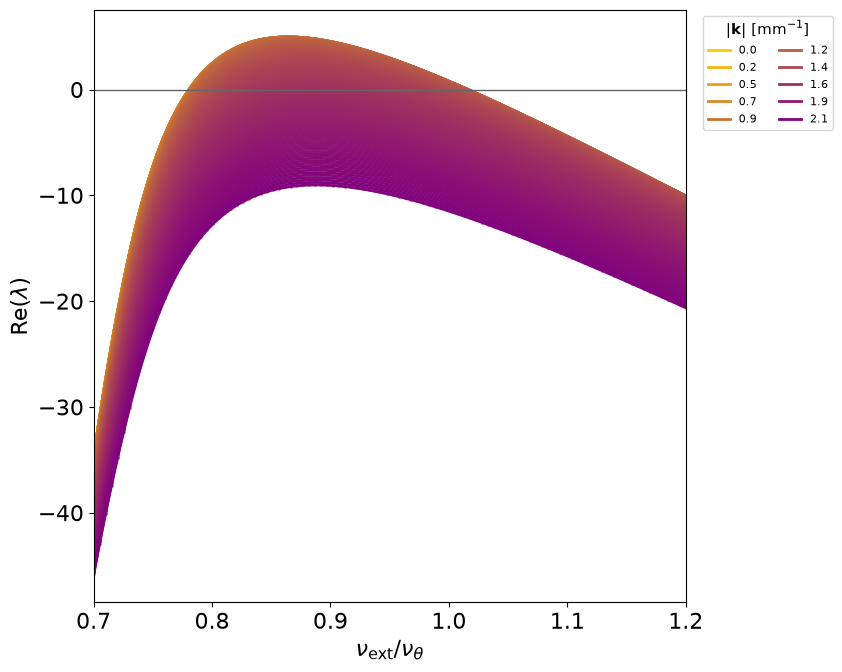

In [7]:
def display_segments(x, y):
    indices = np.flatnonzero(np.isfinite(y))
    if not len(indices):
        return []
    runs = np.split(indices, np.flatnonzero(np.diff(indices) > 1) + 1)
    segments = []
    for ids in runs:
        xx, yy = x[ids], y[ids]
        if len(ids) == 1:
            segments.append((xx, yy))
            continue
        xq_local = np.linspace(xx[0], xx[-1], PT_MORE)
        if INTERPOLATION == "linear" or len(ids) == 2:
            yq_local = np.interp(xq_local, xx, yy)
        elif INTERPOLATION == "pchip":
            yq_local = PchipInterpolator(xx, yy)(xq_local)
        elif INTERPOLATION == "spline":
            yq_local = CubicSpline(xx, yy)(xq_local)
        elif INTERPOLATION == "makima":
            try:
                yq_local = Akima1DInterpolator(xx, yy, method="makima")(xq_local)
            except TypeError as error:
                raise RuntimeError("This SciPy lacks makima; set INTERPOLATION='pchip'.") from error
        else:
            raise ValueError("Unknown INTERPOLATION")
        if SMOOTH_DISPLAY:
            window = min(SMOOTH_WINDOW, len(yq_local))
            if window % 2 == 0:
                window -= 1
            if window >= 3:
                yq_local = savgol_filter(yq_local, window, polyorder=2)
        segments.append((xq_local, yq_local))
    return segments

def format_input_axis(ax):
    ax.set_xlabel(X_LABEL)
    for position in REFERENCE_X:
        ax.axvline(position, color="0.5", linestyle="--", linewidth=1)
    if X_LIMITS is not None:
        ax.set_xlim(X_LIMITS)

colors = np.linspace([1, .8, 0], [.5, 0, .5], N)
fig_growth, ax = plt.subplots(figsize=(10, 7))
ncurves = max(1, N - OMIT_LAST_K_CURVES)

N_LEGEND = 10
legend_rows = set(np.linspace(
    0, ncurves - 1, min(N_LEGEND, ncurves), dtype=int
))

for row in range(ncurves):
    ax.plot(x_points, peakReLambda[row], ".", ms=2, color=colors[row], alpha=.5)
    for segment_id, (xx, yy) in enumerate(display_segments(x_points, peakReLambda[row])):
        ax.plot(xx, yy, linewidth=2, color=colors[row],
                label=f"{real_k[row]:.1f}" if segment_id == 0 and row in legend_rows else None)
ax.axhline(0, color="0.4", linewidth=1)
ax.set_ylabel(r"Re($\lambda$)")
format_input_axis(ax)
ax.set_box_aspect(1)
ax.set_xlim(0.7, 1.2)
if ax.get_legend_handles_labels()[0]:
    ax.legend(title=r"$|\mathbf{k}|$ [mm$^{-1}$]", bbox_to_anchor=(1.02, 1),
              loc="upper left", fontsize=8, title_fontsize=11, ncol=2)
fig_growth.tight_layout()
fig_growth.savefig("growth_rate.svg", format="svg", bbox_inches="tight")
plt.show()


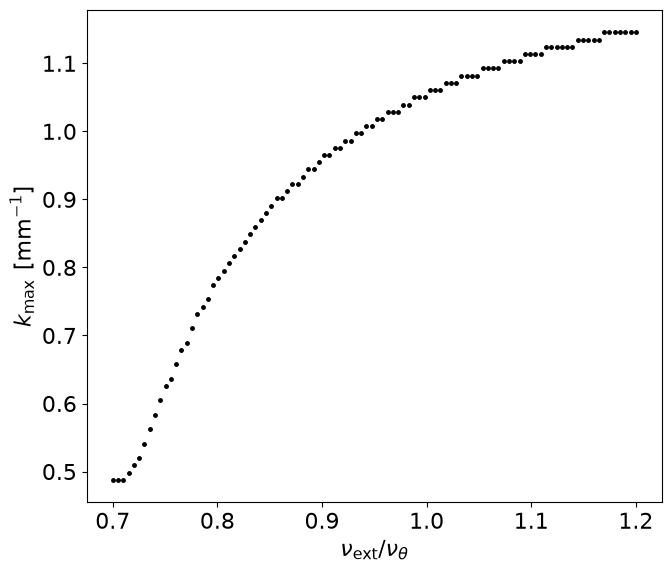

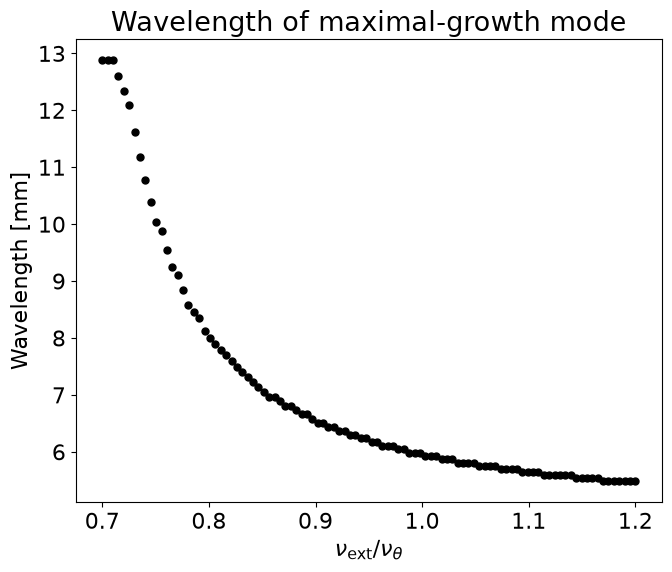

In [9]:

# Plot k of the maximal-growth mode (raw sampled values)
fig_k, ax_k = plt.subplots(figsize=(7, 6))
ax_k.plot(x_points, k_max_list, "k.", markersize=5)
format_input_axis(ax_k)
ax_k.set_ylabel(r"$k_{\max}$ [mm$^{-1}$]")
fig_k.tight_layout()
plt.show()

# Wavelength of the maximal-growth mode
wavelength_mm = np.full(M, np.nan)
positive = np.isfinite(k_max_list) & (k_max_list > 0)
wavelength_mm[positive] = 2 * np.pi / k_max_list[positive]

# k=0 corresponds to infinite wavelength; exclude it from the plot.
fig_wavelength, ax_wavelength = plt.subplots(figsize=(7, 6))
ax_wavelength.plot(x_points, wavelength_mm, "k.", markersize=10)
format_input_axis(ax_wavelength)
ax_wavelength.set_ylabel("Wavelength [mm]")
ax_wavelength.set_title("Wavelength of maximal-growth mode")
fig_wavelength.tight_layout()
plt.show()


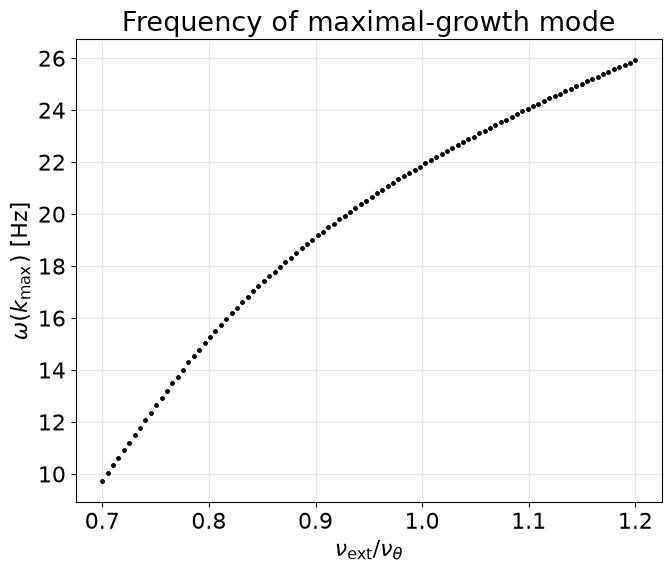

In [5]:
fig_omega, ax_omega = plt.subplots(figsize=(7, 6))

ax_omega.plot(
    x_points,
    np.abs(omega_at_kmax),
    "k.",
    markersize=5
)

format_input_axis(ax_omega)
ax_omega.set_ylabel(r"$\omega(k_{\max})$ [Hz]")
ax_omega.set_title("Frequency of maximal-growth mode")
ax_omega.grid(True, alpha=.3)

fig_omega.tight_layout()
plt.show()

## Save derived results
The following cell writes the two original output datasets as .mat files plus one combined .npz file. It preserves the original k=0 values in k_max_list; wavelength_mm is NaN at those points. Rerunning this cell replaces these derived files. A skipped/failed fit is saved as NaN, not as a zero curve.

In [6]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
savemat(OUTPUT_DIR / "MF_kappa_vs_nu.mat", {
    "x_points": x_points, "k_points": k_points, "xq": xq, "yq": yq,
    "fit_parameters": fit_parameters, "fit_mask": fit_mask,
    "input_scale": INPUT_SCALE,
}, oned_as="row")
savemat(OUTPUT_DIR / "WaveLength_Predicted.mat", {
    "Iext_list": Iext_list, "k_max_list": k_max_list,
    "wavelength_mm": wavelength_mm, "max_growth": max_growth,
    "input_scale": INPUT_SCALE,
}, oned_as="row")
np.savez_compressed(
    OUTPUT_DIR / "spatial_stability_summary.npz",
    Iext_list=Iext_list,
    x_points=x_points,
    real_k=real_k,
    peakReLambda=peakReLambda,
    peakOmega=peakOmega,
    k_max_list=k_max_list,
    max_growth=max_growth,
    omega_at_kmax=omega_at_kmax,
    wavelength_mm=wavelength_mm,
    xq=xq,
    yq=yq,
    fit_parameters=fit_parameters,
    fit_mask=fit_mask,
    input_scale=INPUT_SCALE,
    max_log_objective=MAX_LOG_OBJECTIVE,
    g=G
)